<a href="https://colab.research.google.com/github/x-rohanpatil/DAV-lab-/blob/main/DAV_lab_07_linearMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simple and multiple linear regression: building models ,checking assumptions and evaluating using R^2 and RMSE


importing aall the things needed


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error

load the dataset

In [ ]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
df = pd.read_csv('housing_clean.csv')
df.head()

Saving housing_clean.csv to housing_clean (1).csv


,Area,Rooms,Age,Location_Score,Price
0,778,1,6,3,5081030
1,2148,4,27,8,11863210
2,1909,3,3,5,11371453
3,1478,3,16,3,9079771
4,1466,3,14,4,7502204


simple linear regression

In [ ]:
#only one variable considered (area).train_test_split() keeps 20% of the rows testing .80% to train.
x_simple = df[['Area']]
y = df['Price']

x_tr, x_te, y_tr, y_te = train_test_split(x_simple, y, test_size=0.2, random_state=42)

model_simple = LinearRegression()
model_simple.fit(x_tr, y_tr)

pred_simple = model_simple.predict(x_te)

print('SIMPLE REGRESSION')
print('R²:', round(r2_score(y_te, pred_simple), 2))
print('RMSE:', round(np.sqrt(mean_squared_error(y_te, pred_simple)), 2))



SIMPLE REGRESSION
R²: 0.94
RMSE: 809207.7


multiple linear regression

In [ ]:
#four input features
x_multi = df[['Area', 'Rooms', 'Age', 'Location_Score']]

x_tr2,x_te2,y_tr2,y_te2 = train_test_split(x_multi,y,test_size=0.2,random_state=42)

model_multi = LinearRegression()
model_multi.fit(x_tr2,y_tr2)

pred_multi = model_multi.predict(x_te2)

print('MULTIPLE REGRESSION')
print('R²:', round(r2_score(y_te2, pred_multi), 3))
print('RMSE:', round(np.sqrt(mean_squared_error(y_te2, pred_multi)), 2))

MULTIPLE REGRESSION
R²: 0.977
RMSE: 495063.19


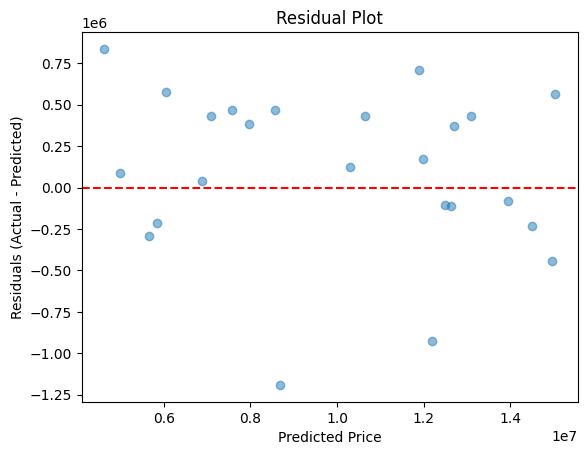

In [ ]:
residuals = y_te2 - pred_multi
plt.scatter(pred_multi, residuals, alpha=0.5)
plt.axhline(0,color='red',linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residual Plot')
plt.show()
